MANUFACTURING DEFECTS DATASET - EDA

About Dataset

This dataset contains simulated data related to manufacturing defects observed during quality control processes. It includes information such as defect type, detection date, location within the product, severity level, inspection method used, and repair costs. This dataset can be used for analyzing defect patterns, improving quality control processes, and assessing the impact of defects on product quality and production costs. Columns:

    defect_id: Unique identifier for each defect.
    product_id: Identifier for the product associated with the defect.
    defect_type: Type or category of the defect (e.g., cosmetic, functional, structural).
    defect_description: Description of the defect.
    defect_date: Date when the defect was detected.
    defect_location: Location within the product where the defect was found (e.g., surface, component).
    severity: Severity level of the defect (e.g., minor, moderate, critical).
    inspection_method: Method used to detect the defect (e.g., visual inspection, automated testing).
    repair_action: Action taken to repair or address the defect.  
    repair_cost: Cost incurred to repair the defect (in local currency).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("defects_data.csv")
df.head()

,defect_id,product_id,defect_type,defect_date,defect_location,severity,inspection_method,repair_cost
0,1,15,Structural,6/6/2024,Component,Minor,Visual Inspection,245.47
1,2,6,Functional,4/26/2024,Component,Minor,Visual Inspection,26.87
2,3,84,Structural,2/15/2024,Internal,Minor,Automated Testing,835.81
3,4,10,Functional,3/28/2024,Internal,Critical,Automated Testing,444.47
4,5,14,Cosmetic,4/26/2024,Component,Minor,Manual Testing,823.64


In [6]:
df.isna().sum()

defect_id            0
product_id           0
defect_type          0
defect_date          0
defect_location      0
severity             0
inspection_method    0
repair_cost          0
dtype: int64

In [7]:
df.duplicated().any()

np.False_

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   defect_id          1000 non-null   int64  
 1   product_id         1000 non-null   int64  
 2   defect_type        1000 non-null   str    
 3   defect_date        1000 non-null   str    
 4   defect_location    1000 non-null   str    
 5   severity           1000 non-null   str    
 6   inspection_method  1000 non-null   str    
 7   repair_cost        1000 non-null   float64
dtypes: float64(1), int64(2), str(5)
memory usage: 110.4 KB


The dataset consists of 1,000 records and 8 columns.
It includes both numerical and categorical features related to manufacturing defects.
The defect_date column is currently stored as an object and will be converted to a datetime format for time-based analysis.

In [9]:
df['defect_date'] = pd.to_datetime(df['defect_date'])

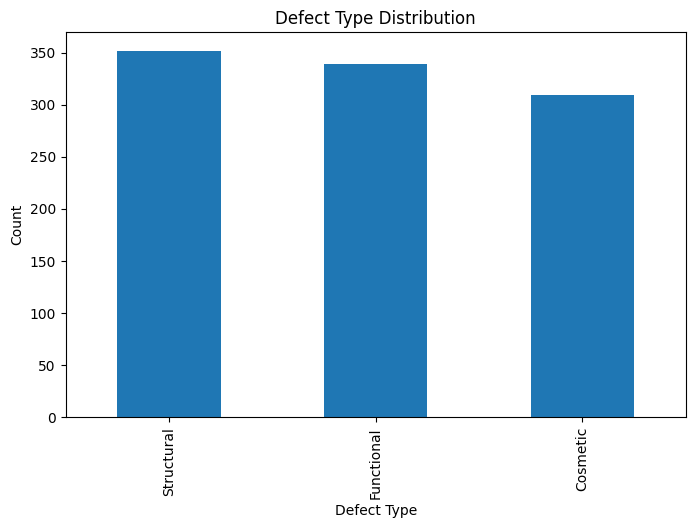

In [10]:
plt.figure(figsize=(8, 5))
df['defect_type'].value_counts().plot(kind='bar')
plt.title("Defect Type Distribution")
plt.xlabel("Defect Type")
plt.ylabel("Count")
plt.show()

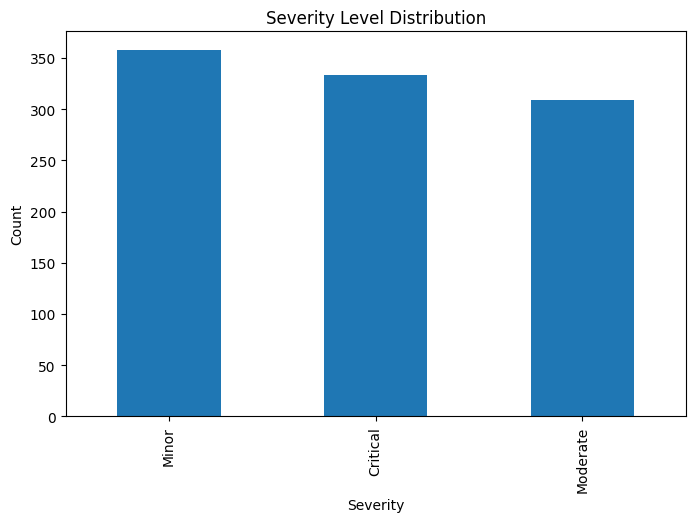

In [11]:
plt.figure(figsize=(8, 5))
df['severity'].value_counts().plot(kind='bar')
plt.title("Severity Level Distribution")
plt.xlabel("Severity")
plt.ylabel("Count")
plt.show()

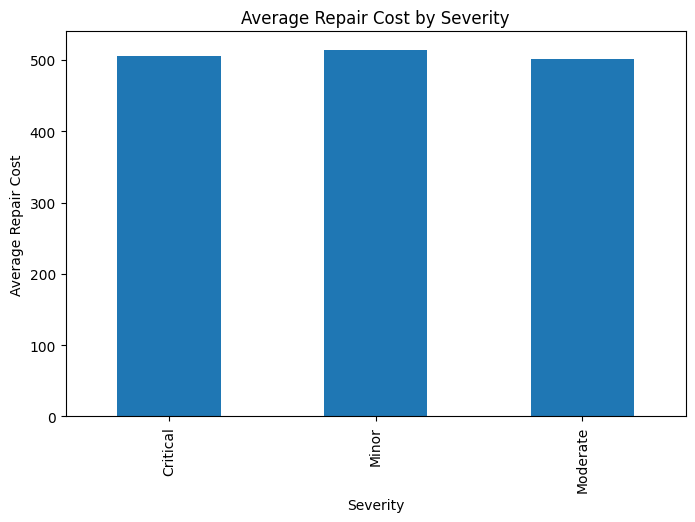

In [12]:
plt.figure(figsize=(8, 5))
df.groupby('severity')['repair_cost'].mean().plot(kind='bar')
plt.title("Average Repair Cost by Severity")
plt.xlabel("Severity")
plt.ylabel("Average Repair Cost")
plt.show()

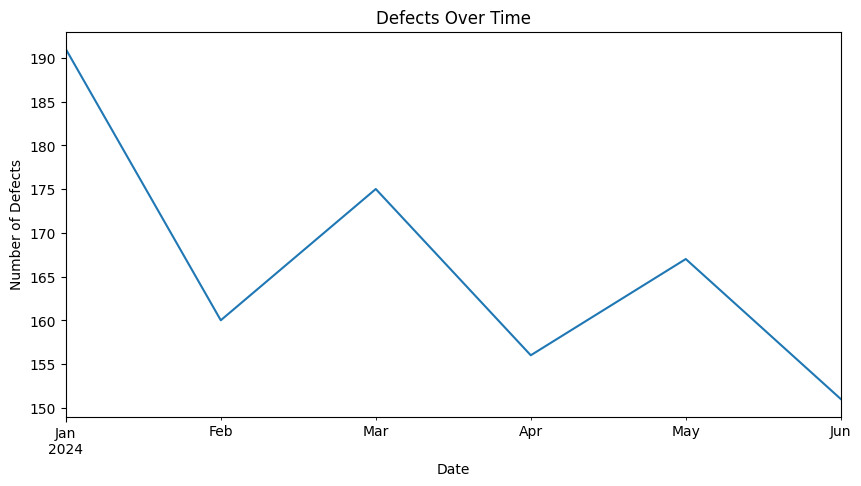

In [16]:
defects_over_time = df.resample('ME', on='defect_date').size()

plt.figure(figsize=(10, 5))
defects_over_time.plot()
plt.title("Defects Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Defects")
plt.show()